## Πρώτη Προσέγγιση (Project Root):

In [2]:
import sys
from pathlib import Path
import logging

# Add the project root to Python path
project_root = Path("D:/Projects/LegalTextAnalysis")
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

# Configure logger with UTF-8 support
logger = logging.getLogger(__name__)
logger.setLevel(logging.INFO)

# StreamHandler for console logging (without Greek characters for compatibility)
console_handler = logging.StreamHandler(sys.stdout)
console_handler.setLevel(logging.INFO)
console_formatter = logging.Formatter('%(asctime)s - %(name)s - %(levelname)s - %(message)s')
console_handler.setFormatter(console_formatter)

# FileHandler for logging to file with UTF-8 encoding
log_file_path = project_root / "logs/notebook.log"
file_handler = logging.FileHandler(log_file_path, encoding='utf-8')
file_handler.setLevel(logging.INFO)
file_handler.setFormatter(console_formatter)

# Add handlers to logger
logger.addHandler(console_handler)
logger.addHandler(file_handler)

# Test logger with both English and Greek messages (log only English in console)
try:
    logger.info("Testing logger initialization")
    # Only log Greek message to the file to avoid console encoding issues
    logger.info("Λειτουργεί καταγραφή στα Ελληνικά (αποθηκεύτηκε στο αρχείο καταγραφής)")
except Exception as e:
    print(f"Logger error: {str(e)}")


2024-11-30 16:12:26,667 - __main__ - INFO - Testing logger initialization
2024-11-30 16:12:26,667 - __main__ - INFO - Testing logger initialization
2024-11-30 16:12:26,669 - __main__ - INFO - Λειτουργεί καταγραφή στα Ελληνικά (αποθηκεύτηκε στο αρχείο καταγραφής)
2024-11-30 16:12:26,669 - __main__ - INFO - Λειτουργεί καταγραφή στα Ελληνικά (αποθηκεύτηκε στο αρχείο καταγραφής)


## Σταδιακή Εισαγωγή των Modules:

In [4]:
# Σταδιακή εισαγωγή των utilities με έλεγχο 
try:
    from scripts.utils.viz_utils import VisualizationUtils
    logger.info("Επιτυχής εισαγωγή του VisualizationUtils")
except ImportError as e:
    logger.error(f"Σφάλμα στην εισαγωγή του VisualizationUtils: {e}")

try:
    from scripts.utils.db_utils import DatabaseUtils
    logger.info("Επιτυχής εισαγωγή του DatabaseUtils")
except ImportError as e:
    logger.error(f"Σφάλμα στην εισαγωγή του DatabaseUtils: {e}")

try:
    from scripts.utils.data_preprocessor import LegalDataPreprocessor
    logger.info("Επιτυχής εισαγωγή του LegalDataPreprocessor")
except ImportError as e:
    logger.error(f"Σφάλμα στην εισαγωγή του LegalDataPreprocessor: {e}")


2024-11-30 16:14:08,127 - __main__ - INFO - Επιτυχής εισαγωγή του VisualizationUtils
2024-11-30 16:14:08,127 - __main__ - INFO - Επιτυχής εισαγωγή του VisualizationUtils
2024-11-30 16:14:08,128 - __main__ - INFO - Επιτυχής εισαγωγή του DatabaseUtils
2024-11-30 16:14:08,128 - __main__ - INFO - Επιτυχής εισαγωγή του DatabaseUtils
2024-11-30 16:14:08,137 - __main__ - INFO - Επιτυχής εισαγωγή του LegalDataPreprocessor
2024-11-30 16:14:08,137 - __main__ - INFO - Επιτυχής εισαγωγή του LegalDataPreprocessor


## Αρχικοποίηση των Αντικειμένων:

In [6]:
# Αρχικοποίηση των αντικειμένων
try:
    # Δημιουργία των βασικών αντικειμένων
    viz = VisualizationUtils()
    db = DatabaseUtils()  # Δεν χρειάζεται το connection attribute

    # Δοκιμαστικό ερώτημα για επιβεβαίωση της σύνδεσης
    result = db.query_database("SELECT COUNT(*) as count FROM legal_cases")[0]
    logger.info(f"Συνολικός αριθμός υποθέσεων: {result['count']}")

    # Δημιουργία του preprocessor με το db object
    preprocessor = LegalDataPreprocessor(db)  # Περνάμε το db object, όχι connection

    logger.info("Επιτυχής αρχικοποίηση όλων των αντικειμένων")

except Exception as e:
    logger.error(f"Σφάλμα κατά την αρχικοποίηση: {e}")


2024-11-30 16:15:16,768 - __main__ - INFO - Συνολικός αριθμός υποθέσεων: 24985
2024-11-30 16:15:16,768 - __main__ - INFO - Συνολικός αριθμός υποθέσεων: 24985
2024-11-30 16:15:16,769 - __main__ - INFO - Επιτυχής αρχικοποίηση όλων των αντικειμένων
2024-11-30 16:15:16,769 - __main__ - INFO - Επιτυχής αρχικοποίηση όλων των αντικειμένων


## Δημιουργία Γραφημάτων:

d:\Projects\LegalTextAnalysis\.venv\Lib\site-packages\seaborn\categorical.py:632: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
D:\Projects\LegalTextAnalysis\scripts\utils\viz_utils.py:101: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45)
d:\Projects\LegalTextAnalysis\.venv\Lib\site-packages\seaborn\categorical.py:632: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
D:\Projects\LegalTextAnalysis\scripts\utils\viz_utils.py:106: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45)


2024-11-30 16:16:31,595 - __main__ - INFO - Επιτυχής δημιουργία γραφημάτων
2024-11-30 16:16:31,595 - __main__ - INFO - Επιτυχής δημιουργία γραφημάτων


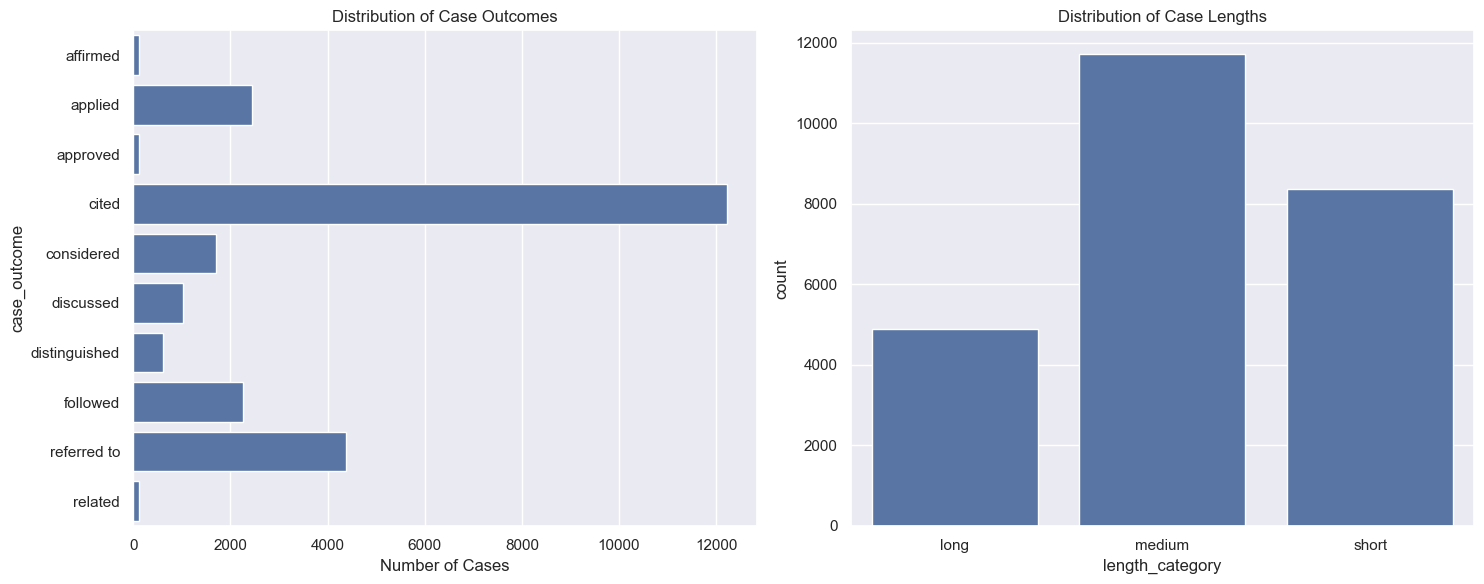

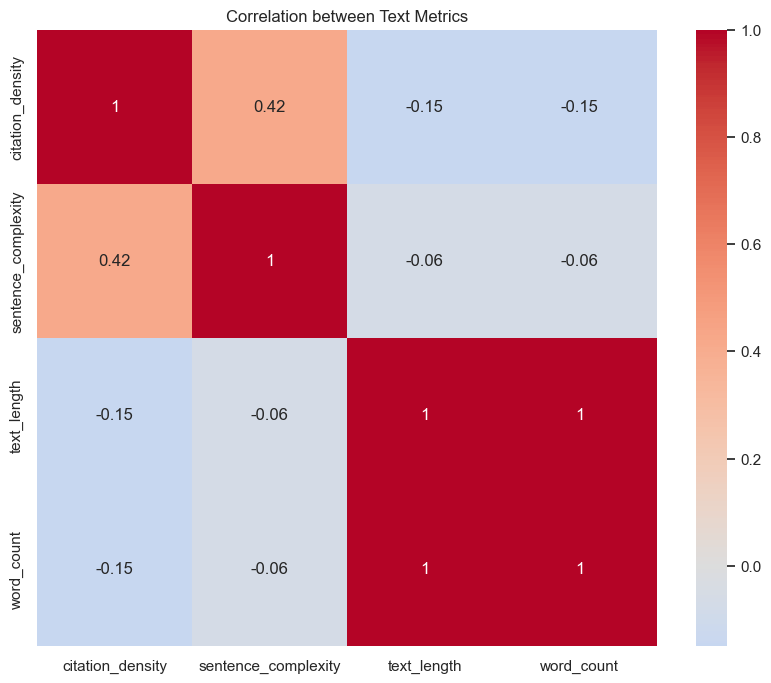

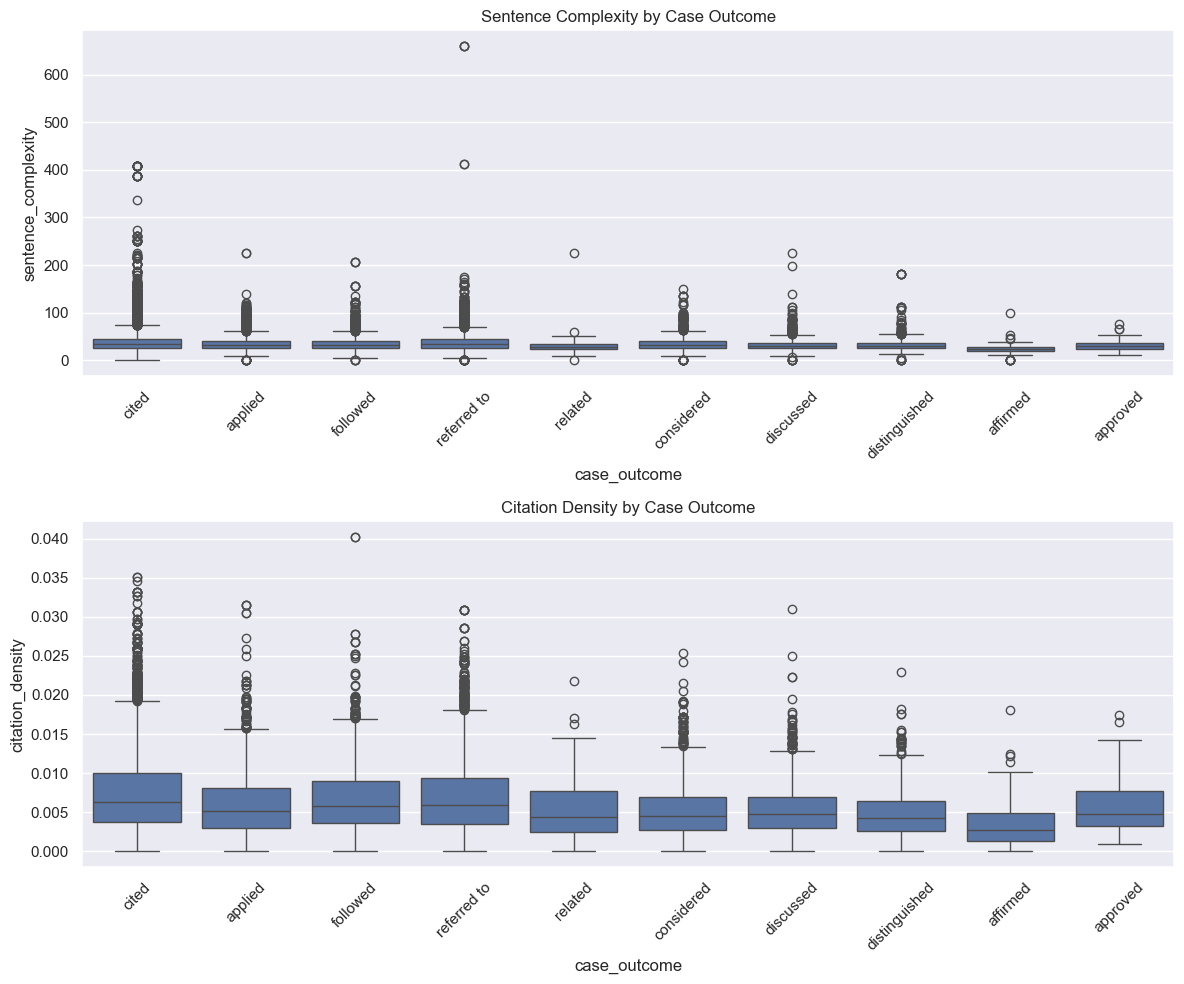

In [9]:
# Ορισμός του data_dir
data_dir = project_root / "data"
if not data_dir.exists():
    data_dir.mkdir(parents=True, exist_ok=True)

# Δημιουργία γραφημάτων
try:
    # Δημιουργία των γραφημάτων με πλήρεις διαδρομές
    viz.plot_case_distributions(save_path=str(data_dir / "case_distributions.png"))
    viz.plot_metrics_heatmap(save_path=str(data_dir / "metrics_heatmap.png"))
    viz.plot_complexity_by_outcome(save_path=str(data_dir / "complexity_by_outcome.png"))
    
    logger.info("Επιτυχής δημιουργία γραφημάτων")
except Exception as e:
    logger.error(f"Σφάλμα κατά τη δημιουργία γραφημάτων: {e}")
